# Apophis and the 13 April 2029 flyby

(99942) Apophis is a ~340 m asteroid that will pass inside the ring of geostationary satellites on
**13 April 2029**, bright enough to see with the naked eye from Europe and Africa. It once topped
the impact-risk lists; today the question is how precisely we know the pass, and what it does
to the orbit.

In this notebook PyRoOrb fits Apophis's full observation record (optical **and radar**) and answers:

1. **When and how close?** We check the closest approach against JPL's published value.
2. **How sure are we?** The ephemeris carries its own 1σ error ellipse.
3. **What does the thermal (Yarkovsky) push do?** The fit detects it unaided; we compare it with
   JPL's value and see how far it moves the 2029 pass.
4. **What does Earth do to Apophis?** We compare the orbit before and after the flyby with JPL Horizons.

Every number is checked against JPL, so a hidden problem would show up as a disagreement.

In [1]:
# Load the PyRoOrb settings file (.env: data folders) before the engine is imported.
from pyroorb.envfile import load_env_file
load_env_file()

import warnings
import numpy as np
import matplotlib.pyplot as plt
import pyroorb

# Future UTC dates make astropy warn that leap seconds are not yet known; harmless here.
warnings.filterwarnings("ignore", message=".*dubious year.*")
plt.rcParams.update({"figure.figsize": (8, 4.5), "figure.dpi": 110, "axes.grid": True,
                     "grid.alpha": 0.3})
print("PyRoOrb", pyroorb.__version__)

PyRoOrb 0.9.0


JPL integrates Apophis with the 16 most massive asteroids as perturbers (their `SB441-N16`
kernel). We do the same, using PyRoOrb's *whole-fit* asteroid mode. Download the kernel once with
`pyroorb-fetch-data --asteroids` (~600 MB). The setting must be in place before the first fit.

In [2]:
import os
from pyroorb import datadirs

ephem_dir = os.environ.get("PYROORB_EPHEM_DIR") or str(datadirs.table_dir("ephem"))
os.environ["PYROORB_ASTEROIDS_PATH"] = os.path.join(ephem_dir, "sb441-n16.bsp")

## Fit the orbit

Two calls: fetch everything the MPC has (radar delay/Doppler comes along automatically) and fit.
The fit decides on its own whether a non-gravitational term is needed (a BIC test).

In [3]:
obs = pyroorb.fetch_observations("99942")
fit = pyroorb.fit_orbit(obs, designation="99942")

d = fit.as_dict()
print(f"{fit.n_observations()} of {fit.n_total_observations()} optical observations used, "
      f"{len(obs.meta['radar'])} radar measurements, arc {fit.arc_length_days() / 365.25:.1f} yr")
print(f"RMS {fit.rms_residual():.3f} arcsec | force model {d['force_model']} | "
      f"non-grav model: {d['nongrav_model']}")
print(f"A2 = {d['nongrav_params']['A2']:.4e} +/- {d['nongrav_sigmas']['A2']:.1e} au/d^2")

9429 of 9517 optical observations used, 50 radar measurements, arc 17.2 yr
RMS 0.467 arcsec | force model ASSIST(DE440+GR+16ast) | non-grav model: yarkovsky
A2 = -2.9194e-14 +/- 6.1e-17 au/d^2


A **negative A2** is a transverse push against the direction of motion. That is the Yarkovsky
signature of a *retrograde* rotator: Apophis spirals slowly inward.

## Check 1: the Yarkovsky term against JPL

In [4]:
import json, urllib.parse, urllib.request

def jpl(api, **params):
    """Query one of JPL's SSD APIs (sbdb, cad, ...) and return the JSON."""
    url = f"https://ssd-api.jpl.nasa.gov/{api}.api?" + urllib.parse.urlencode(params)
    with urllib.request.urlopen(url, timeout=60) as r:
        return json.load(r)

sbdb = jpl("sbdb", sstr="99942")["orbit"]
jpl_a2 = next(p for p in sbdb["model_pars"] if p["name"] == "A2")
a2, sa2 = d["nongrav_params"]["A2"], d["nongrav_sigmas"]["A2"]
print(f"PyRoOrb A2 = {a2:.4e} +/- {sa2:.1e}   ({fit.n_observations()} obs)")
print(f"JPL     A2 = {float(jpl_a2['value']):.4e} +/- {float(jpl_a2['sigma']):.1e}   "
      f"({sbdb['n_obs_used']} obs, orbit {sbdb['orbit_id']})")
print(f"difference = {(a2 - float(jpl_a2['value'])) / float(jpl_a2['sigma']):+.1f} JPL sigma")

PyRoOrb A2 = -2.9194e-14 +/- 6.1e-17   (9429 obs)
JPL     A2 = -2.9020e-14 +/- 1.9e-16   (7370 obs, orbit 220)
difference = -0.9 JPL sigma


The two agree to within JPL's 1σ. PyRoOrb's formal σ is smaller for two reasons: it fits
A2 alone, while JPL also fits a radial A1, and it uses the observations made since JPL's last
solution.

## Check 2: the closest approach

`pyroorb.ephemeris` with site `500` (the geocentre) gives the distance `delta_au` and the 1σ
sky-plane error ellipse at each step. A 5-second grid around the pass finds the minimum.

In [5]:
from astropy.time import Time
AU_KM = 149597870.7

t0 = Time("2029-04-13 21:30", scale="utc").jd
rows = pyroorb.ephemeris(fit, t0, t0 + 30 / 1440, step=5 / 86400, site="500", full=False)
ca = min(rows, key=lambda r: r["delta_au"])
ca_km = ca["delta_au"] * AU_KM
ellipse_km = np.radians(ca["unc_smaj_arcsec"] / 3600) * ca_km    # 1-sigma, mostly along-track

cad = jpl("cad", des="99942", **{"date-min": "2029-04-01", "date-max": "2029-05-01", "dist-max": "0.01"})
c = dict(zip(cad["fields"], cad["data"][0]))
jpl_t = Time(float(c["jd"]), format="jd", scale="tdb").utc
jpl_km, jpl_lo, jpl_hi = (float(c[k]) * AU_KM for k in ("dist", "dist_min", "dist_max"))

print(f"            closest approach (UTC)    distance from Earth's centre")
print(f"PyRoOrb   {ca['date_iso']}         {ca_km:9.1f} km   (1-sigma sky-plane ellipse {ellipse_km:.0f} km)")
print(f"JPL CAD   {jpl_t.iso[:19]}         {jpl_km:9.1f} km   (3-sigma range {jpl_lo:.1f} - {jpl_hi:.1f} km)")
print(f"difference: {ca_km - jpl_km:+.1f} km, {(ca['jd_utc'] - jpl_t.jd) * 86400:+.0f} s")

            closest approach (UTC)    distance from Earth's centre
PyRoOrb   2029-04-13 21:45:05           38012.6 km   (1-sigma sky-plane ellipse 49 km)
JPL CAD   2029-04-13 21:45:03           38011.5 km   (3-sigma range 38008.2 - 38014.7 km)
difference: +1.1 km, +1 s


Our closest approach lands **inside JPL's 3σ distance range**. The time agrees to within the
5-second grid. Our position ellipse (~50 km) is mostly *along the track*: it is an
uncertainty in *when* Apophis arrives (about 7 s at 7.4 km/s), not in how close it comes.
That matches JPL's quoted time uncertainty of under a minute.

## The pass, hour by hour

peak brightness V = 3.1


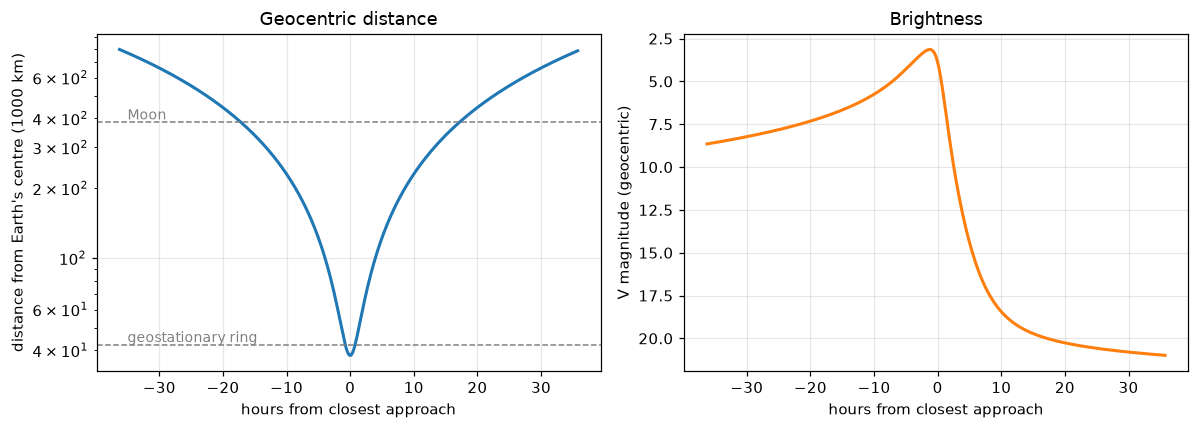

In [6]:
R_EARTH, GEO, MOON = 6378.1, 42164.0, 384400.0
rows = pyroorb.ephemeris(fit, t0 - 1.5, t0 + 1.5, step=10 / 1440, site="500", full=False)
hours = np.array([(r["jd_utc"] - ca["jd_utc"]) * 24 for r in rows])
dist = np.array([r["delta_au"] for r in rows]) * AU_KM
vmag = np.array([r["v_mag"] for r in rows])

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(11, 4))
ax1.plot(hours, dist / 1e3, lw=2, label="Apophis")
for y, lab in [(GEO, "geostationary ring"), (MOON, "Moon")]:
    ax1.axhline(y / 1e3, ls="--", c="gray", lw=1)
    ax1.text(-35, y / 1e3 * 1.03, lab, color="gray", fontsize=9)
ax1.set(xlabel="hours from closest approach", ylabel="distance from Earth's centre (1000 km)",
        yscale="log", title="Geocentric distance")
ax2.plot(hours, vmag, lw=2, c="C1")
ax2.invert_yaxis()
ax2.set(xlabel="hours from closest approach", ylabel="V magnitude (geocentric)",
        title="Brightness")
plt.tight_layout()
print(f"peak brightness V = {vmag.min():.1f}")

## How far does the Yarkovsky push move the 2029 pass?

A2 is ~10⁻¹⁴ au/day², a force smaller than a whisper. Integrated for 16 years, though, it is
not negligible. Take the fitted state (epoch 2013) and switch the thermal force off. Comparing
the two trajectories shows how much of the 2029 geometry rests on it.

*This cell reaches into PyRoOrb's propagator (an internal API, which may change).*

In [7]:
from pyroorb.obs_sources import _force_backend, observer_positions_batch
from pyroorb.ephemerides import _nongrav_pair

backend, _ = _force_backend(fit)
jd = ca["jd_utc"] + np.arange(-3600, 3601, 5) / 86400            # +-1 h around the pass
tt = Time(jd, format="jd", scale="utc").tdb.jd
earth = np.asarray(observer_positions_batch(jd, ["500"] * len(jd), {}))

def closest(nongrav):
    helio = backend.helio_positions_batch(backend.build_base_sim(fit.epoch_tdb), fit.epoch_tdb,
                                          fit.state()[:6], tt, nongrav=nongrav)
    r = np.linalg.norm(np.asarray(helio) - earth, axis=1) * AU_KM
    return r.min()

with_km, without_km = closest(_nongrav_pair(fit)), closest(None)
print(f"with Yarkovsky:    {with_km:9.1f} km")
print(f"without Yarkovsky: {without_km:9.1f} km  ({without_km - with_km:+.0f} km)")

with Yarkovsky:      38012.6 km
without Yarkovsky:   38224.5 km  (+212 km)


Over the 16 years the thermal push moves the closest approach by a couple of hundred km. That is
tiny next to the 38,000 km miss, but about 60 times JPL's 3σ distance uncertainty. A precise
2029 prediction *needs* Yarkovsky in the model. (This switches the force off on the *same*
fitted state; a gravity-only *refit* would absorb part of the drift by shifting the orbit.)

## Check 3: Earth reshapes the orbit

We propagate the fitted orbit to six weeks before and two months after the flyby and compare the
osculating heliocentric elements with JPL Horizons at the same instants.

In [8]:
from pyroorb.orbital_elements import element_vector

def horizons_elements(jd_tdb):
    """JPL Horizons osculating heliocentric ecliptic elements (a, e, i, P) at a TDB JD."""
    q = {"format": "text", "COMMAND": "'99942;'", "EPHEM_TYPE": "ELEMENTS", "CENTER": "'500@10'",
         "TLIST": f"'{jd_tdb}'", "REF_PLANE": "ECLIPTIC", "OUT_UNITS": "AU-D", "CSV_FORMAT": "YES"}
    url = "https://ssd.jpl.nasa.gov/api/horizons.api?" + urllib.parse.urlencode(q)
    with urllib.request.urlopen(url, timeout=60) as r:
        text = r.read().decode()
    f = text.split("$$SOE")[1].split("$$EOE")[0].split(",")
    return float(f[11]), float(f[2]), float(f[4]), float(f[13]) / 365.25   # a, e, i, P (yr)

print(f"{'':10s} {'':8s} {'a (au)':>9s} {'e':>8s} {'i (deg)':>8s} {'P (yr)':>7s}")
for label, date in [("before", "2029-03-05"), ("after", "2029-06-13")]:
    t1 = Time(date, scale="tdb").jd
    state = backend.predict_state(None, fit.epoch_tdb, fit.state()[:6], t1, nongrav=_nongrav_pair(fit))
    a, e, _, _, i, *_rest, P = element_vector(np.asarray(state), t1)
    ha, he, hi, hP = horizons_elements(t1)
    print(f"{label:10s} PyRoOrb  {a:9.5f} {e:8.5f} {i:8.4f} {P:7.4f}")
    print(f"{'':10s} Horizons {ha:9.5f} {he:8.5f} {hi:8.4f} {hP:7.4f}")

                       a (au)        e  i (deg)  P (yr)


before     PyRoOrb    0.92233  0.19122   3.3420  0.8858
           Horizons   0.92233  0.19122   3.3420  0.8858


after      PyRoOrb    1.10306  0.18904   2.2209  1.1585
           Horizons   1.10307  0.18904   2.2210  1.1585


The flyby lifts Apophis's semi-major axis from 0.92 au to 1.10 au. Its period grows from about
0.89 years to 1.16 years, and its inclination drops by more than a degree. The orbit class changes
from **Aten** (a < 1 au) to **Apollo**, and PyRoOrb and Horizons agree on the new orbit to the
digits shown.

## Summary

| | PyRoOrb | JPL |
|---|---|---|
| Yarkovsky A2 | fit unaided | agrees within 1σ |
| 2029 closest approach | ~38,013 km | 38,011.5 km (3σ: ±3.3 km) |
| Orbit after the flyby | Apollo, a ≈ 1.10 au | the same |

About a dozen lines of PyRoOrb reproduce JPL's 2029 prediction from the raw observations.

**Caveats.** The distances above are geocentric (to Earth's centre, not the surface). PyRoOrb's
non-gravitational model here is A2 only. Impact probabilities and keyholes (not shown) are
research features that have not been validated against JPL Sentry.